# Ordenamiento y Búsqueda

## Buscar v/s Ordenar

*   **Búsqueda:** El objetivo es determinar si un elemento específico está presente dentro de una colección y, eventualmente, encontrar la posición exacta que ocupa.
*   **Ordenamiento:** El propósito es reorganizar todos los elementos de una colección siguiendo un criterio o regla específica (por ejemplo, de menor a mayor).

Existe una sinergia crucial entre ambas operaciones. Las estrategias de búsqueda **más eficientes**, como la **búsqueda binaria**, tienen un requisito estricto: *necesitan que los datos estén previamente ordenados*.

---

## Dividir y Conquistar

"Dividir para reinar" (o Dividir y Conquistar) es una estrategia algorítmica fundamental para resolver problemas complejos. En lugar de intentar abordar el problema completo de una sola vez, esta técnica propone un flujo de trabajo de tres pasos:

1.  **Dividir:** Fraccionar el problema original en subproblemas más pequeños del mismo tipo.
2.  **Resolver:** Encontrar la solución a estos subproblemas más pequeños (generalmente de manera recursiva hasta llegar a un caso base trivial).
3.  **Combinar:** Juntar o integrar las soluciones de los subproblemas para construir la solución del problema original grande.

**Aplicaciones en el Ordenamiento:**
Esta estrategia se utiliza en algoritmos de ordenamiento eficientes como:
*   **Merge Sort:** Divide repetidamente la colección en dos mitades hasta llegar a elementos individuales, y luego *combina* esas partes intercalándolas de forma ordenada.
*   **Quick Sort:** Selecciona un elemento "pivote" y *divide* (particiona) el resto de los elementos en dos grupos: los menores al pivote y los mayores al pivote, para luego aplicar la misma lógica a cada grupo.

---

## ¿Por qué usar Dividir y Conquistar?

La razón principal para adoptar la estrategia de Dividir y Conquistar radica en la **optimización extrema del costo temporal (complejidad algorítmica)**. Abordar los problemas fraccionándolos permite reducir drásticamente la cantidad de operaciones matemáticas o comparaciones necesarias.

**1. Reducción exponencial del espacio de trabajo:**
En algoritmos como la búsqueda binaria, aplicar esta lógica significa que en cada paso descartamos la mitad de los datos. La progresión del tamaño del problema disminuye rápidamente: $n \rightarrow \frac{n}{2} \rightarrow \frac{n}{4} \rightarrow \dots$
Esto nos permite pasar de un tiempo lineal $O(n)$ (revisar uno por uno en el peor de los casos) a un tiempo logarítmico $O(log~n)$, lo cual es inmensamente más rápido en conjuntos de datos masivos.

**2. Tiempos de ordenamiento eficientes:**
Para los problemas de ordenamiento, la estrategia de Dividir y Conquistar permite procesar los datos en diferentes "niveles". La relación de recurrencia típica de estos algoritmos se expresa como:

$$T(n) = 2T\left(\frac{n}{2}\right) + \mathcal{O}(n)$$

Esto significa que hay aproximadamente $log_{2}n$ niveles de división, y en cada nivel se procesa un total de $n$ elementos. Como resultado, algoritmos como Merge Sort logran una complejidad de tiempo de $O(n~log~n)$ en todos sus casos (mejor, promedio y peor). Esta es una mejora monumental comparada con algoritmos menos sofisticados que toman un tiempo cuadrático $O(n^{2})$.


Se utiliza Dividir y Conquistar porque **transforma problemas inmanejables en problemas tratables y escalables**.


#Ejercicios

Implemente los siguientes algoritmos de ordenamiento:
* [Bubble sort](https://www.youtube.com/watch?v=0BkoXZBbhfU&list=PLlzjt-kuLwlo6QuXHSZCkITkfn9M2yHg1&index=1)
* [Insertion sort](https://www.youtube.com/watch?v=IniSptbttgg&list=PLlzjt-kuLwlo6QuXHSZCkITkfn9M2yHg1&index=5)
* [Selection sort](https://www.youtube.com/watch?v=MxEooU-8ps8&list=PLlzjt-kuLwlo6QuXHSZCkITkfn9M2yHg1&index=2)
* [Merge sort](https://www.youtube.com/watch?v=o2K0B3EcQ_s&list=PLlzjt-kuLwlo6QuXHSZCkITkfn9M2yHg1&index=4)
* [Quicksort](https://www.youtube.com/watch?v=00LqwHZQuQ4&list=PLlzjt-kuLwlo6QuXHSZCkITkfn9M2yHg1&index=3)

Considere que estos últimos dos usan Divide y Vencerás.

Finalmente, para cada uno, grafique los tiempos de ejecución y compare.

In [1]:
import random
import time
import math
import statistics
import matplotlib.pyplot as plt

In [2]:
#bubble
def bubble_sort(datos):
    n = len(datos)
    for i in range(n):
      for j in range(n - i - 1):
        if datos[j] > datos[j+1]:
          datos[j], datos[j+1] = datos[j+1], datos[j]

    return datos

lista = [1,9,-1, 10, 20]
print(bubble_sort(lista))

[-1, 1, 9, 10, 20]


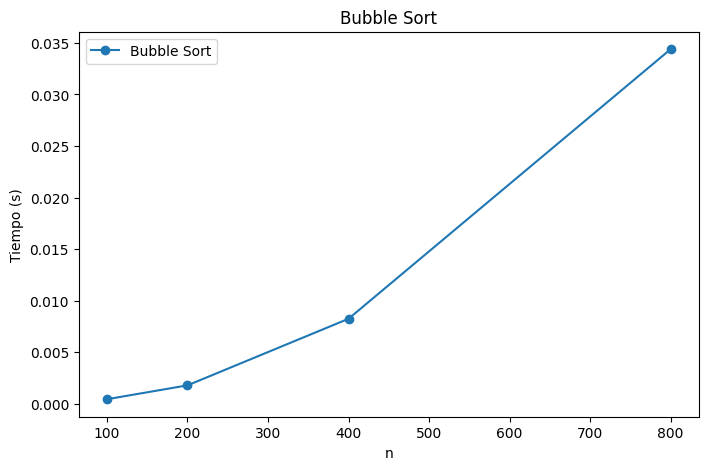

In [13]:
#grafico bubble
tamanos = [100, 200, 400, 800]
tiempos_bubble = []

for n in tamanos:
    muestras = []
    for _ in range(5):
        datos = [random.randint(0, 1_000_000) for _ in range(n)]
        inicio = time.perf_counter()
        bubble_sort(datos)
        muestras.append(time.perf_counter() - inicio)
    tiempos_bubble.append(statistics.median(muestras))

plt.figure(figsize=(8, 5))
plt.plot(tamanos, tiempos_bubble, marker="o", label="Bubble Sort")
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Bubble Sort")
plt.legend()
plt.show()

In [4]:
#insert
def insertion_sort(datos):
    n = len(datos)
    for i in range(1, n):
      j = i - 1
      temp = datos[i]
      while j >= 0 and temp < datos[j]:
        datos[j+1] = datos[j]
        j-=1
      datos[j+1] = temp
    return datos

lista = [1,9,-1, 10, 20]
print(insertion_sort(lista))

[-1, 1, 9, 10, 20]


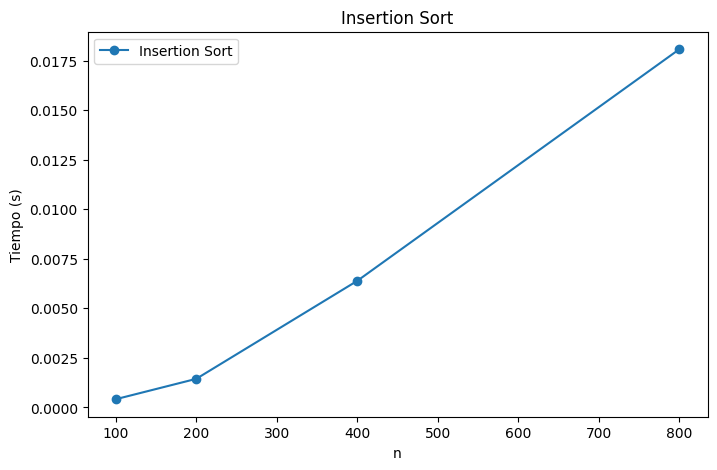

In [16]:
#grafico insert
tamanos = [100, 200, 400, 800]
tiempos_insertion = []

for n in tamanos:
    muestras = []
    for _ in range(5):
        datos = [random.randint(0, 1_000_000) for _ in range(n)]
        inicio = time.perf_counter()
        insertion_sort(datos)
        muestras.append(time.perf_counter() - inicio)
    tiempos_insertion.append(statistics.median(muestras))

plt.figure(figsize=(8, 5))
plt.plot(tamanos, tiempos_insertion, marker="o", label="Insertion Sort")
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Insertion Sort")
plt.legend()
plt.show()

In [6]:
#selection
def selection_sort(datos):
    for i in range(len(datos)):
        min_idx = i
        for j in range(i + 1, len(datos)):
            if datos[min_idx] > datos[j]:
                min_idx = j
        datos[i], datos[min_idx] = datos[min_idx], datos[i]
    return datos

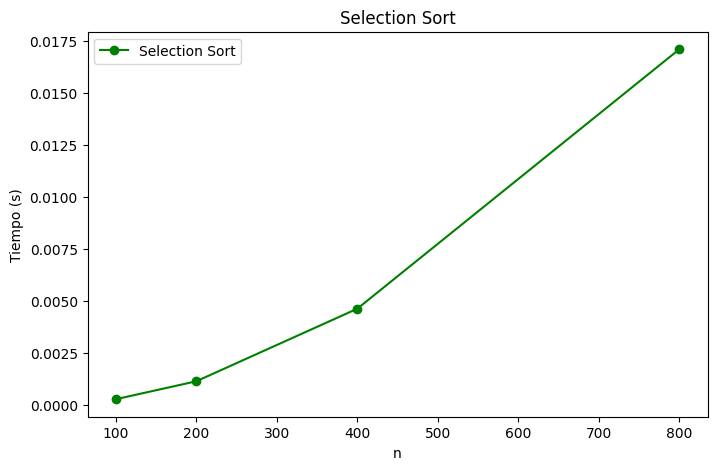

In [7]:
#grafico selection
tamanos = [100, 200, 400, 800]
tiempos_selection = []

for n in tamanos:
    muestras = []
    for _ in range(5):
        datos = [random.randint(0, 1_000_000) for _ in range(n)]
        inicio = time.perf_counter()
        selection_sort(datos)
        muestras.append(time.perf_counter() - inicio)
    tiempos_selection.append(statistics.median(muestras))

plt.figure(figsize=(8, 5))
plt.plot(tamanos, tiempos_selection, marker="o", label="Selection Sort", color="green")
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Selection Sort")
plt.legend()
plt.show()

In [8]:
#merge
def merge(a, b):
    resultado = []
    i = j = 0
    # Compara los primeros elementos de ambas mitades y agrega el menor.
    while i < len(a) and j < len(b):
        if a[i] <= b[j]:
            resultado.append(a[i])
            i += 1
        else:
            resultado.append(b[j])
            j += 1
    # Si sobraron elementos en alguna mitad, los agrega al final.
    resultado.extend(a[i:])
    resultado.extend(b[j:])
    return resultado

def merge_sort(datos):
    if len(datos) <= 1:
        return datos

    # Fase de División
    medio = len(datos) // 2
    izquierda = merge_sort(datos[:medio])
    derecha = merge_sort(datos[medio:])

    # Fase de Combinación (Conquista)
    return merge(izquierda, derecha)


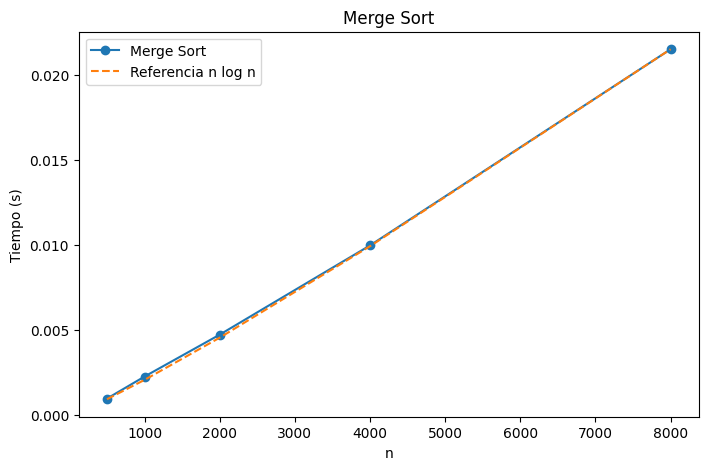

In [9]:
#grafico merge
tamanos_merge = [500, 1_000, 2_000, 4_000, 8_000]
tiempos_merge = []

for n in tamanos_merge:
    muestras = []
    for _ in range(5):
        datos = [random.randint(0, 1_000_000) for _ in range(n)]
        inicio = time.perf_counter()
        merge_sort(datos)
        muestras.append(time.perf_counter() - inicio)
    tiempos_merge.append(statistics.median(muestras))

# Línea de referencia n log n
referencia_nlogn = [n * math.log2(n) for n in tamanos_merge]
factor = tiempos_merge[-1] / referencia_nlogn[-1]
referencia_nlogn = [x * factor for x in referencia_nlogn]

plt.figure(figsize=(8, 5))
plt.plot(tamanos_merge, tiempos_merge, marker="o", label="Merge Sort")
plt.plot(tamanos_merge, referencia_nlogn, linestyle="--", label="Referencia n log n")
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Merge Sort")
plt.legend()
plt.show()

In [10]:
#quick
def particion(datos, low, high):
    p = datos[high]
    i = low -1
    for j in range(low, high):
      if datos[j] <= p:
        i+= 1
        datos[i], datos[j] = datos[j], datos[i]

    datos[i+1],datos[high] = datos[high], datos[i+1]
    return i + 1


def quick_sort(datos, low, high):
    if low < high:
      pivote = particion(datos, low, high)

      quick_sort(datos, low, pivote - 1)
      quick_sort(datos, pivote + 1, high)

    return datos


lista = [1,9,-1, 10, 20]
print(quick_sort(lista, 0, 4))


[-1, 1, 9, 10, 20]


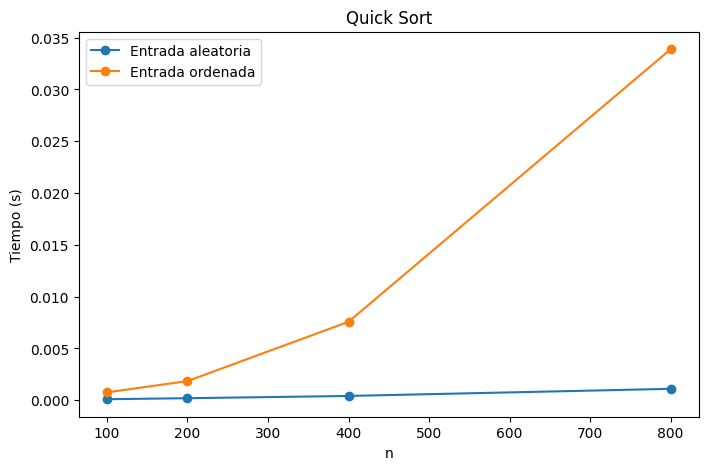

In [11]:
#grafico quick
tamanos_quick = [100, 200, 400, 800]
tiempos_random = []
tiempos_ordenados = []

for n in tamanos_quick:
    muestras_random = []
    muestras_ordenadas = []
    for _ in range(5):
        datos_random = list(range(n))
        random.shuffle(datos_random)
        inicio = time.perf_counter()

        quick_sort(datos_random, 0, len(datos_random) - 1)
        muestras_random.append(time.perf_counter() - inicio)

        datos_ordenados = list(range(n))
        inicio = time.perf_counter()
        quick_sort(datos_ordenados, 0, len(datos_ordenados) - 1)
        muestras_ordenadas.append(time.perf_counter() - inicio)

    tiempos_random.append(statistics.median(muestras_random))
    tiempos_ordenados.append(statistics.median(muestras_ordenadas))

plt.figure(figsize=(8, 5))
plt.plot(tamanos_quick, tiempos_random, marker="o", label="Entrada aleatoria")
plt.plot(tamanos_quick, tiempos_ordenados, marker="o", label="Entrada ordenada")
plt.xlabel("n")
plt.ylabel("Tiempo (s)")
plt.title("Quick Sort")
plt.legend()
plt.show()

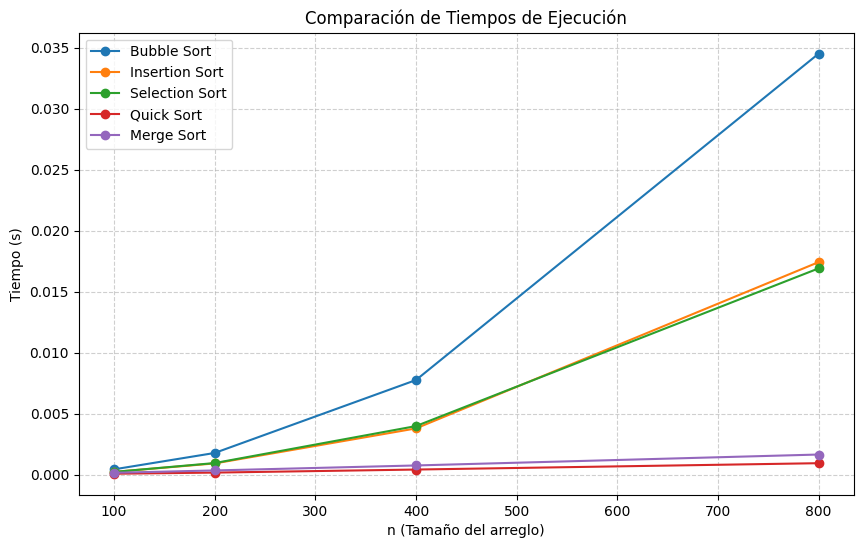

In [17]:
#comparación
tamanos_comparacion = [100, 200, 400, 800]

tiempos_bubble_comp = []
tiempos_insertion_comp = []
tiempos_selection_comp = []
tiempos_quick_comp = []
tiempos_merge_comp = []

for n in tamanos_comparacion:
    m_bubble, m_insertion, m_selection, m_quick, m_merge = [], [], [], [], []

    for _ in range(5):
        datos_base = [random.randint(0, 1_000_000) for _ in range(n)]

        # Bubble Sort
        datos = datos_base.copy()
        inicio = time.perf_counter()
        bubble_sort(datos)
        m_bubble.append(time.perf_counter() - inicio)

        # Insertion Sort
        datos = datos_base.copy()
        inicio = time.perf_counter()
        insertion_sort(datos)
        m_insertion.append(time.perf_counter() - inicio)

        # Selection Sort
        datos = datos_base.copy()
        inicio = time.perf_counter()
        selection_sort(datos)
        m_selection.append(time.perf_counter() - inicio)

        # Quick Sort
        datos = datos_base.copy()
        inicio = time.perf_counter()
        quick_sort(datos, 0, len(datos) - 1)
        m_quick.append(time.perf_counter() - inicio)

        # Merge Sort
        datos = datos_base.copy()
        inicio = time.perf_counter()
        merge_sort(datos)
        m_merge.append(time.perf_counter() - inicio)

    tiempos_bubble_comp.append(statistics.median(m_bubble))
    tiempos_insertion_comp.append(statistics.median(m_insertion))
    tiempos_selection_comp.append(statistics.median(m_selection))
    tiempos_quick_comp.append(statistics.median(m_quick))
    tiempos_merge_comp.append(statistics.median(m_merge))

plt.figure(figsize=(10, 6))
plt.plot(tamanos_comparacion, tiempos_bubble_comp, marker="o", label="Bubble Sort")
plt.plot(tamanos_comparacion, tiempos_insertion_comp, marker="o", label="Insertion Sort")
plt.plot(tamanos_comparacion, tiempos_selection_comp, marker="o", label="Selection Sort")
plt.plot(tamanos_comparacion, tiempos_quick_comp, marker="o", label="Quick Sort")
plt.plot(tamanos_comparacion, tiempos_merge_comp, marker="o", label="Merge Sort")

plt.xlabel("n (Tamaño del arreglo)")
plt.ylabel("Tiempo (s)")
plt.title("Comparación de Tiempos de Ejecución")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()